# Notebook 02 — Train and compare triage models

**Input:** `data/processed/triage_dataset.csv` (from Notebook 01)

**Approach**
1. Hold out **20 %** of the data as a test set that is *never* used for training or tuning (it is evaluated once, in Notebook 03).
2. Turn the text into numbers with **TF-IDF** features:
   - **word n-grams** (1–2 words), e.g. *"chest pain"*, *"homa kali"*
   - **character n-grams** (3–5 letters), which cope with spelling mistakes and Kiswahili word forms (e.g. *nina**kohoa***, *ana**kohoa***)
3. Compare four classic classifiers with **5-fold stratified cross-validation** on the training set:
   Logistic Regression, Complement Naive Bayes, Linear SVM and Random Forest.
4. Tune the best model's hyper-parameters and save it for final evaluation.

**Why these metrics?** The classes are imbalanced, so accuracy alone is misleading.
We report **macro-F1** (treats all four levels equally) and **emergency recall** — the share of real emergencies the model catches.
Missing an emergency is the most dangerous error, so emergency recall is the key safety metric.

In [1]:
from pathlib import Path
import time
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import ComplementNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import make_scorer, recall_score

warnings.filterwarnings('ignore', category=UserWarning)

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_FILE     = ROOT / 'data' / 'processed' / 'triage_dataset.csv'
PROCESSED_DIR = ROOT / 'data' / 'processed'
MODELS_DIR    = ROOT / 'models'
REPORTS_DIR   = ROOT / 'reports'
FIGURES_DIR   = REPORTS_DIR / 'figures'
for d in (MODELS_DIR, FIGURES_DIR):
    d.mkdir(parents=True, exist_ok=True)

TRIAGE_LEVELS = ['self-care', 'pharmacy', 'clinic', 'emergency']
RANDOM_STATE = 42

# Run in a single process: parallel workers use too much RAM on an 8 GB laptop,
# and the dataset is small enough that this is still fast.
N_JOBS = 1

print('Project root:', ROOT)
print('Dataset found:', DATA_FILE.exists())

Project root: C:\Users\thuku\telemedicine-chatbot\ml
Dataset found: True


## 1. Load data and create the hold-out test set
The split is **stratified** (each triage level keeps the same proportion in train and test) and also balanced by language.
The two sets are saved so Notebook 03 evaluates on exactly the same test data.

In [2]:
df = pd.read_csv(DATA_FILE)
print('Rows:', len(df))

# Stratify on triage + language so Kiswahili examples appear in both sets
strata = df['triage'] + '_' + df['language']
train_df, test_df = train_test_split(df, test_size=0.20, stratify=strata, random_state=RANDOM_STATE)

train_df.to_csv(PROCESSED_DIR / 'train.csv', index=False)
test_df.to_csv(PROCESSED_DIR / 'test.csv', index=False)

split_summary = pd.DataFrame({
    'train': train_df['triage'].value_counts(),
    'test':  test_df['triage'].value_counts(),
}).reindex(TRIAGE_LEVELS)
split_summary.loc['total'] = split_summary.sum()
split_summary

Rows: 1458


,train,test
triage,,
self-care,111,28
pharmacy,282,70
clinic,693,174
emergency,80,20
total,1166,292


In [3]:
X_train, y_train = train_df['text'], train_df['triage']
X_test,  y_test  = test_df['text'],  test_df['triage']
print(f'Training examples: {len(X_train)}   Test examples (held out): {len(X_test)}')

Training examples: 1166   Test examples (held out): 292


## 2. Feature extraction (TF-IDF)

In [4]:
def make_features():
    return FeatureUnion([
        ('words', TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=1, sublinear_tf=True)),
        ('chars', TfidfVectorizer(lowercase=True, analyzer='char_wb', ngram_range=(3, 5), min_df=2, sublinear_tf=True)),
    ])

# Quick look at the size of the feature space
feats = make_features().fit(X_train)
n_words = len(feats.transformer_list[0][1].vocabulary_)
n_chars = len(feats.transformer_list[1][1].vocabulary_)
print(f'Word n-gram features: {n_words:,}')
print(f'Char n-gram features: {n_chars:,}')
print(f'Total features:       {n_words + n_chars:,}')

Word n-gram features: 11,357
Char n-gram features: 11,699
Total features:       23,056


## 3. The four candidate models
`class_weight='balanced'` makes mistakes on small classes (self-care, emergency) cost more, which counters the imbalance.

In [5]:
models = {
    'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=3000, C=10, random_state=RANDOM_STATE),
    'Complement Naive Bayes': ComplementNB(alpha=0.3),
    'Linear SVM': LinearSVC(class_weight='balanced', C=1.0, random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=300, class_weight='balanced_subsample',
                                            n_jobs=N_JOBS, random_state=RANDOM_STATE),
}

pipelines = {name: Pipeline([('features', make_features()), ('clf', clf)]) for name, clf in models.items()}
list(pipelines)

['Logistic Regression',
 'Complement Naive Bayes',
 'Linear SVM',
 'Random Forest']

## 4. Five-fold cross-validation on the training set

In [6]:
emergency_recall = make_scorer(recall_score, labels=['emergency'], average='macro', zero_division=0)

scoring = {
    'accuracy':         'accuracy',
    'precision_macro':  'precision_macro',
    'recall_macro':     'recall_macro',
    'f1_macro':         'f1_macro',
    'emergency_recall': emergency_recall,
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rows, fold_scores = [], {}
for name, pipe in pipelines.items():
    start = time.time()
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=N_JOBS)
    secs = time.time() - start
    fold_scores[name] = res['test_f1_macro']
    rows.append({
        'model': name,
        'accuracy':         res['test_accuracy'].mean(),
        'precision (macro)': res['test_precision_macro'].mean(),
        'recall (macro)':   res['test_recall_macro'].mean(),
        'F1 (macro)':       res['test_f1_macro'].mean(),
        'F1 std':           res['test_f1_macro'].std(),
        'emergency recall': res['test_emergency_recall'].mean(),
        'time (s)':         secs,
    })
    print(f'{name:<24} macro-F1 = {rows[-1]["F1 (macro)"]:.3f}   emergency recall = {rows[-1]["emergency recall"]:.3f}   ({secs:.1f}s)')

results = pd.DataFrame(rows).sort_values('F1 (macro)', ascending=False).reset_index(drop=True)
results.to_csv(REPORTS_DIR / 'model_comparison_cv.csv', index=False)
results.style.format({c: '{:.3f}' for c in results.columns if c not in ('model', 'time (s)')} | {'time (s)': '{:.1f}'}) \
             .highlight_max(subset=['accuracy', 'precision (macro)', 'recall (macro)', 'F1 (macro)', 'emergency recall'], color='#c8e6c9')

Logistic Regression      macro-F1 = 0.842   emergency recall = 0.713   (5.3s)
Complement Naive Bayes   macro-F1 = 0.721   emergency recall = 0.512   (1.6s)
Linear SVM               macro-F1 = 0.840   emergency recall = 0.700   (2.0s)
Random Forest            macro-F1 = 0.752   emergency recall = 0.537   (15.0s)


,model,accuracy,precision (macro),recall (macro),F1 (macro),F1 std,emergency recall,time (s)
0,Logistic Regression,0.904,0.855,0.832,0.842,0.030,0.713,5.3
1,Linear SVM,0.905,0.861,0.827,0.840,0.026,0.700,2.0
2,Random Forest,0.846,0.831,0.708,0.752,0.023,0.537,15.0
3,Complement Naive Bayes,0.833,0.755,0.702,0.721,0.021,0.512,1.6


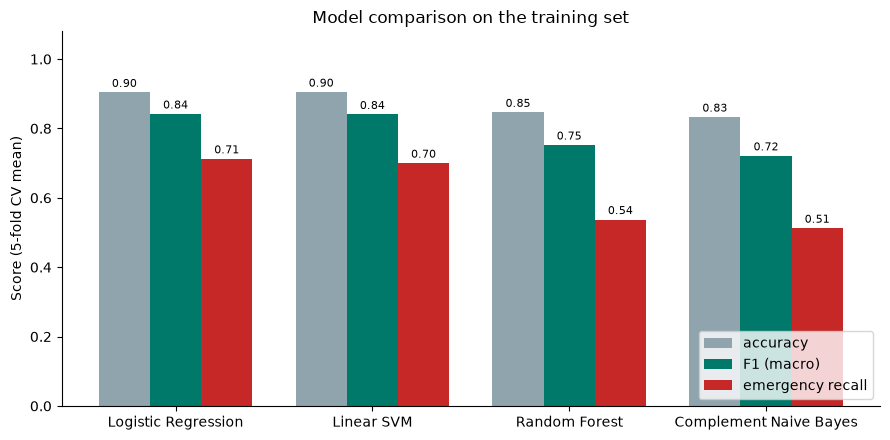

In [7]:
# Comparison chart for the report
metrics = ['accuracy', 'F1 (macro)', 'emergency recall']
colors = ['#90a4ae', '#00796b', '#c62828']
x = np.arange(len(results))
w = 0.26

fig, ax = plt.subplots(figsize=(9, 4.5))
for i, (m, c) in enumerate(zip(metrics, colors)):
    bars = ax.bar(x + (i - 1) * w, results[m], w, label=m, color=c)
    ax.bar_label(bars, fmt='%.2f', fontsize=8, padding=2)
ax.set_xticks(x, results['model'])
ax.set_ylim(0, 1.08)
ax.set_ylabel('Score (5-fold CV mean)')
ax.set_title('Model comparison on the training set')
ax.legend(loc='lower right')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'model_comparison.png', dpi=200)
plt.show()

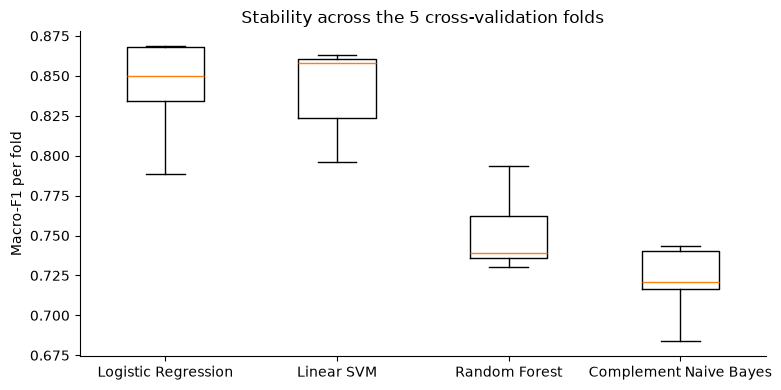

In [8]:
# Fold-by-fold stability (how much the score varies between folds)
fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot([fold_scores[m] for m in results['model']])
ax.set_xticks(range(1, len(results) + 1), results['model'])
ax.set_ylabel('Macro-F1 per fold')
ax.set_title('Stability across the 5 cross-validation folds')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'cv_stability.png', dpi=200)
plt.show()

## 5. Choose and tune the best model
The best model is chosen by **macro-F1**, using emergency recall as the tie-breaker (scores within 0.01 count as a tie).
A small grid search then tunes its main settings, again with 5-fold cross-validation on the training set only.

In [9]:
best_f1 = results['F1 (macro)'].max()
contenders = results[results['F1 (macro)'] >= best_f1 - 0.01]
best_name = contenders.sort_values(['emergency recall', 'F1 (macro)'], ascending=False).iloc[0]['model']
print('Selected model:', best_name)

param_grids = {
    'Logistic Regression':    {'clf__C': [1, 5, 10, 30], 'features__words__ngram_range': [(1, 1), (1, 2)]},
    'Complement Naive Bayes': {'clf__alpha': [0.1, 0.3, 0.5, 1.0], 'features__words__ngram_range': [(1, 1), (1, 2)]},
    'Linear SVM':             {'clf__C': [0.3, 1, 3, 10], 'features__words__ngram_range': [(1, 1), (1, 2)]},
    'Random Forest':          {'clf__n_estimators': [300, 500], 'clf__min_samples_leaf': [1, 2]},
}

search = GridSearchCV(pipelines[best_name], param_grids[best_name], cv=cv,
                      scoring={'f1_macro': 'f1_macro', 'emergency_recall': emergency_recall},
                      refit='f1_macro', n_jobs=N_JOBS)
search.fit(X_train, y_train)

print('Best parameters:', search.best_params_)
print(f'Tuned CV macro-F1: {search.best_score_:.3f}')
er = search.cv_results_['mean_test_emergency_recall'][search.best_index_]
print(f'Tuned CV emergency recall: {er:.3f}')

Selected model: Logistic Regression
Best parameters: {'clf__C': 10, 'features__words__ngram_range': (1, 1)}
Tuned CV macro-F1: 0.854
Tuned CV emergency recall: 0.762


In [10]:
# Grid search results table (for the appendix)
grid = pd.DataFrame(search.cv_results_)
param_cols = [c for c in grid.columns if c.startswith('param_')]
grid_table = (grid[param_cols + ['mean_test_f1_macro', 'mean_test_emergency_recall']]
              .rename(columns=lambda c: c.replace('param_', '').replace('mean_test_', 'CV '))
              .sort_values('CV f1_macro', ascending=False)
              .reset_index(drop=True))
grid_table.to_csv(REPORTS_DIR / 'grid_search_results.csv', index=False)
grid_table.round(3)

,clf__C,features__words__ngram_range,CV f1_macro,CV emergency_recall
0,10,"(1, 1)",0.854,0.762
1,5,"(1, 1)",0.850,0.775
2,30,"(1, 1)",0.846,0.738
3,10,"(1, 2)",0.842,0.712
4,30,"(1, 2)",0.842,0.700
5,5,"(1, 2)",0.840,0.738
6,1,"(1, 2)",0.832,0.788
7,1,"(1, 1)",0.828,0.800


## 6. Make sure the model gives a confidence score
The backend needs a **confidence** for each prediction (e.g. *"emergency, 92 %"*).
Logistic Regression, Naive Bayes and Random Forest give probabilities directly. A Linear SVM does not, so it is wrapped in
`CalibratedClassifierCV`, which learns to convert its scores into probabilities.

In [11]:
final_model = search.best_estimator_

if not hasattr(final_model, 'predict_proba'):
    print('Wrapping the SVM with probability calibration...')
    tuned_svm = final_model.named_steps['clf']
    final_model = Pipeline([
        ('features', final_model.named_steps['features']),
        ('clf', CalibratedClassifierCV(tuned_svm, method='sigmoid', cv=5)),
    ])
    final_model.fit(X_train, y_train)

print('Classes:', list(final_model.classes_))
print('Supports predict_proba:', hasattr(final_model, 'predict_proba'))

Classes: ['clinic', 'emergency', 'pharmacy', 'self-care']
Supports predict_proba: True


In [12]:
# Quick sanity check on a few new sentences (not part of any dataset)
samples = [
    'I have a runny nose and I am sneezing a lot',
    'I have heartburn after eating',
    'I have had fever and chills for three days',
    'I have severe chest pain and I cannot breathe',
    'Nina homa na kichwa kinauma kwa siku tatu',
    'Mtoto wangu ana degedege',
]
proba = final_model.predict_proba(samples)
pd.DataFrame({
    'text': samples,
    'prediction': final_model.predict(samples),
    'confidence': proba.max(axis=1).round(2),
})

,text,prediction,confidence
0,I have a runny nose and I am sneezing a lot,self-care,0.97
1,I have heartburn after eating,pharmacy,0.88
2,I have had fever and chills for three days,clinic,0.72
3,I have severe chest pain and I cannot breathe,emergency,0.99
4,Nina homa na kichwa kinauma kwa siku tatu,clinic,0.73
5,Mtoto wangu ana degedege,emergency,0.70


## 7. Save the trained model
Saved to `models/candidate_model.joblib`. Notebook 03 evaluates it **once** on the held-out test set and exports the final version for the API.

In [13]:
joblib.dump({
    'model': final_model,
    'model_name': best_name,
    'best_params': search.best_params_,
    'cv_f1_macro': float(search.best_score_),
    'cv_emergency_recall': float(er),
    'labels': TRIAGE_LEVELS,
    'trained_on': len(X_train),
}, MODELS_DIR / 'candidate_model.joblib')

print('Saved:', MODELS_DIR / 'candidate_model.joblib')

Saved: C:\Users\thuku\telemedicine-chatbot\ml\models\candidate_model.joblib


## Observations (fill in for the report)
- Which model scored best on macro-F1, and by how much?
- Was the best model also the best at **emergency recall**? If not, explain the trade-off you chose.
- How stable were the scores across folds (box plot)?
- Linear models (Logistic Regression / Linear SVM) usually do well on short TF-IDF text; Random Forest often struggles with very sparse, high-dimensional features.